# 02 · Pronóstico

**Objetivo:** pronosticar la demanda de autos y obtener la **demanda anual** y la **desviación estándar del error de pronóstico**, que después usan los modelos de inventario (consigna, sección 2).

**Entrada:** `outputs/serie_mensual.csv`, que genera `01_serie_demanda.ipynb`. Hay que correr ese notebook antes que este.  
**Salida:** `outputs/pronostico_12_meses.csv`, `outputs/demanda_anual.csv` y `outputs/pronostico.png`, que usa el notebook 03.

Antes de usar cualquier número en el informe: *Restart* y *Run All*.

**Recorrido:**

1. Qué modelo: Winters (sección 4).
2. Qué versión de Winters: la aditiva (sección 5).
3. Qué constantes: α = β = γ = 0,1 (sección 6).
4. Resultado: demanda anual y desvío del error (sección 7).

**Cómo leer las referencias:** en la presentación *Modelos de Pronósticos*, el número es el de la diapositiva. En la *Guía 4* y en la planificación de la cátedra, es la página del PDF. Las clases de 2025 se citan por fecha. Cada decisión aclara si tiene **respaldo de la cátedra** o si es **criterio propio**.

## 1. Decisión: pronosticar el total y repartirlo

Se pronostica la serie `Total` (Clásicos más Vintage) y después se reparte entre las dos líneas con las proporciones históricas.

**Respaldo de la cátedra:** es la lectura literal de la consigna, que habla de partir de las "ventas agregadas" y de usar las "proporciones históricas de venta desagregada" (consigna, sección 2).

**Limitación:** el reparto supone una proporción fija, y mes a mes la proporción de Clásicos va del 29% al 78% (`01_serie_demanda.ipynb`, sección 7). La sección 8 vuelve sobre esto.

## 2. Carga de la serie

Se lee la serie mensual que armó el notebook 01 y se toma la columna `Total`. `asfreq("MS")` le indica a la librería que hay un dato por mes, el primer día de cada mes.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

CARPETA_SALIDA = "outputs"

serie = pd.read_csv(os.path.join(CARPETA_SALIDA, "serie_mensual.csv"), index_col="mes")
serie.index = pd.PeriodIndex(serie.index, freq="M").to_timestamp()
total = serie["Total"].astype(float).asfreq("MS")

print("Meses:", len(total), "| desde", total.index[0].strftime("%Y-%m"), "hasta", total.index[-1].strftime("%Y-%m"))

Meses: 29 | desde 2003-01 hasta 2005-05


## 3. Cómo se comparan los modelos

Cada modelo pronostica cada mes usando solo los datos hasta el mes anterior, como en las tablas de las diapositivas 24 y 28. El error de cada mes es real menos pronóstico, y se resume con tres medidas: RMSE, MAE y MAPE (diapositivas 14, 16 y 17).

- **Respaldo de la cátedra:** elegir el modelo comparando esas medidas sobre los datos que ya se tienen (diapositivas 11, 23 y 28).

- **Criterio propio: todos los modelos se miden en los mismos 17 meses, de enero de 2004 a mayo de 2005.**
  - *Por qué hace falta:* cada modelo puede empezar a pronosticar en un mes distinto. La media móvil de 12 meses necesita un año de datos previos, así que su primer pronóstico es enero de 2004. Los otros modelos pueden empezar antes.
  - *Qué pasaría sin esa regla:* si cada modelo se midiera en todos los meses que puede pronosticar, los errores se calcularían sobre meses distintos y no serían comparables. Como la demanda tiene un pico en noviembre, quedar dentro o fuera de la ventana cambiaría mucho el error.
  - *Qué se hace:* se usa la ventana más corta que todos cubren, que la fija la media móvil de 12 meses.
  - *Efecto a favor:* la ventana incluye el pico de noviembre de 2004, que es lo que distingue a los modelos con estacionalidad de los que no la tienen.
  - *Limitación:* la ventana tiene un solo noviembre (el de 2003 queda afuera), así que es una muestra chica.

- **Constantes de suavizado:** en todos los modelos se usa 0,1. La Guía 4 usa α = β = 0,1 (ejercicio 2, inciso 3, p. 1), y en la clase del 3/9/2025 se dijo que la bibliografía sugiere valores entre 0,1 y 0,3. La sección 6 muestra qué cambia con otros valores.

**Ojo:** esta ventana de 17 meses es solo para comparar modelos. El desvío del error que va al informe se calcula sobre los 29 meses (sección 7), por eso el RMSE de Winters aditivo da 411 acá y 401 allá.

Dos funciones que se usan en el resto del notebook:

- `medir` calcula RMSE, MAE y MAPE de un pronóstico en la ventana de enero de 2004 a mayo de 2005.
- `winters` ajusta el método de Winters con las tres constantes iguales. `estacionalidad` es `"mul"` (multiplicativa) o `"add"` (aditiva). Los valores iniciales (nivel, pendiente y factores estacionales) los estima la librería con los datos; la sección 6 explica por qué no se usa el método de la diapositiva 56.

En la librería, `fittedvalues` es justamente el pronóstico de un mes hacia adelante para cada mes de la serie.

In [2]:
VENTANA = slice("2004-01", "2005-05")

def medir(nombre, pronostico):
    error = (total - pronostico).loc[VENTANA]
    return {
        "modelo": nombre,
        "RMSE": round((error ** 2).mean() ** 0.5),
        "MAE": round(error.abs().mean()),
        "MAPE %": round((error.abs() / total.loc[VENTANA]).mean() * 100, 1),
    }

def winters(datos, estacionalidad, constante):
    modelo = ExponentialSmoothing(datos, trend="add", seasonal=estacionalidad,
                                  seasonal_periods=12, initialization_method="estimated")
    return modelo.fit(smoothing_level=constante, smoothing_trend=constante, smoothing_seasonal=constante)

## 4. ¿Qué modelo? Winters contra los demás

Se comparan los modelos de la unidad:

- **Media móvil** con k = 3, 6 y 12 (diapositivas 22 a 26): pronostica el promedio de los últimos k meses. En el código, `rolling(k).mean()` promedia los últimos k meses y `shift(1)` lo corre un mes, para que el pronóstico de cada mes use solo los meses anteriores. Los valores 3 y 6 están en la tabla de la diapositiva 26; k = 12 es criterio propio, porque promedia un año entero.
- **Suavizado exponencial** (diapositivas 27 y 28): corrige el pronóstico anterior con una parte α del último error.
- **Holt** (diapositivas 48 y 49): le agrega una pendiente.
- **Winters** (diapositivas 52 a 55): le agrega factores estacionales. Se prueban sus dos versiones, multiplicativa y aditiva; la sección 5 explica la diferencia.

In [3]:
filas = []

for k in [3, 6, 12]:
    pronostico = total.rolling(k).mean().shift(1)
    filas.append(medir(f"Media móvil, k = {k}", pronostico))

suavizado = ExponentialSmoothing(total, initialization_method="estimated").fit(smoothing_level=0.1)
filas.append(medir("Suavizado exponencial", suavizado.fittedvalues))

holt = ExponentialSmoothing(total, trend="add", initialization_method="estimated").fit(smoothing_level=0.1, smoothing_trend=0.1)
filas.append(medir("Holt", holt.fittedvalues))

filas.append(medir("Winters multiplicativo", winters(total, "mul", 0.1).fittedvalues))
filas.append(medir("Winters aditivo", winters(total, "add", 0.1).fittedvalues))

pd.DataFrame(filas).set_index("modelo")

,RMSE,MAE,MAPE %
modelo,,,
"Media móvil, k = 3",1352,1069,53.3
"Media móvil, k = 6",1436,1129,63.3
"Media móvil, k = 12",1124,697,39.0
Suavizado exponencial,1195,731,38.0
Holt,1243,976,60.0
Winters multiplicativo,400,311,19.3
Winters aditivo,411,329,21.6


**Resultado:** Winters erra unas tres veces menos que los demás: un RMSE de unos 400 autos, contra 1.100 a 1.450. Los otros modelos no tienen estacionalidad: en noviembre pronostican un mes común y se quedan muy cortos, y después del pico la mayoría pronostica de más. La diapositiva 29 lo anticipa: si los datos muestran tendencia o estacionalidad, los modelos de nivel no alcanzan.

**Elección: Winters.**

## 5. ¿Qué versión de Winters? La aditiva

Las dos versiones difieren en cómo combinan el nivel con la estacionalidad.

**Multiplicativa** (diapositivas 9, 54 y 55): el factor de cada mes es un porcentaje del nivel. Si el nivel crece 24%, el pico de noviembre también crece 24%.

- $L_t = \alpha \, D_t / s_{t-c} + (1 - \alpha)(L_{t-1} + B_{t-1})$
- $s_t = \gamma \, D_t / L_t + (1 - \gamma) \, s_{t-c}$
- $F_{t+k} = (L_t + k \, B_t) \, s_{t+k-c}$

**Aditiva:** el factor de cada mes es una cantidad fija de autos que se suma al nivel. Si el nivel crece, el pico crece poco. Las fórmulas son las mismas, restando en lugar de dividir; la de la pendiente, $B_t$, no cambia:

- $L_t = \alpha \, (D_t - s_{t-c}) + (1 - \alpha)(L_{t-1} + B_{t-1})$
- $s_t = \gamma \, (D_t - L_t) + (1 - \gamma) \, s_{t-c}$
- $F_{t+k} = L_t + k \, B_t + s_{t+k-c}$

**Fuente externa:** la versión aditiva no está en las diapositivas. Está en la documentación de la librería statsmodels, y es la que usa la función PRONOSTICO.ETS de Excel, según la documentación de Microsoft (versión "AAA": error, tendencia y estacionalidad aditivos).

La celda compara cuánto creció el año completo con cuánto creció noviembre.

In [4]:
anual_2003 = total.loc["2003"].sum()
anual_2004 = total.loc["2004"].sum()
noviembre_2003 = total.loc["2003-11-01"]
noviembre_2004 = total.loc["2004-11-01"]

print("Año completo: 2003 =", int(anual_2003), "| 2004 =", int(anual_2004),
      "| creció", round((anual_2004 / anual_2003 - 1) * 100, 1), "%")
print("Noviembre:    2003 =", int(noviembre_2003), "| 2004 =", int(noviembre_2004),
      "| creció", round((noviembre_2004 / noviembre_2003 - 1) * 100, 1), "%")

Año completo: 2003 = 19818 | 2004 = 24574 | creció 24.0 %
Noviembre:    2003 = 6009 | 2004 = 5974 | creció -0.6 %


El año creció 24% y noviembre se mantuvo. Con la versión multiplicativa, noviembre de 2004 tendría que haber dado unos 7.400 autos. Lo que pasó se parece más a la aditiva.

La celda siguiente compara las dos versiones, con α = β = γ = 0,1, en tres chequeos:

1. **Error en la ventana común** (sección 3).
2. **Enero a mayo de 2005 sin verlos:** se ajusta el modelo solo con 2003 y 2004, se pronostican esos 5 meses y se compara la suma con la real. **Respaldo de la cátedra:** la Unidad 6 incluye la validación de los modelos (planificación, p. 8). La forma de hacerlo es **criterio propio**.
3. **Noviembre de 2005 pronosticado**, contra los dos noviembres reales, de unos 6.000 autos.

In [5]:
hasta_2004 = total.loc[:"2004-12"]
print("Enero a mayo de 2005, real:", int(total.loc["2005-01":].sum()))

filas = []
for estacionalidad, nombre in [("mul", "Winters multiplicativo"), ("add", "Winters aditivo")]:
    con_todo = winters(total, estacionalidad, 0.1)
    sin_2005 = winters(hasta_2004, estacionalidad, 0.1)
    fila = medir(nombre, con_todo.fittedvalues)
    fila["ene-may 2005 pronosticado"] = round(sin_2005.forecast(5).sum())
    fila["nov 2005 pronosticado"] = round(con_todo.forecast(12).loc["2005-11-01"])
    filas.append(fila)

pd.DataFrame(filas).set_index("modelo")

Enero a mayo de 2005, real: 9716


,RMSE,MAE,MAPE %,ene-may 2005 pronosticado,nov 2005 pronosticado
modelo,,,,,
Winters multiplicativo,400,311,19.3,8402,8180
Winters aditivo,411,329,21.6,8874,6665


**Resultado:** en la ventana común empatan. En los otros dos chequeos gana la aditiva: se acerca más a lo que se vendió en enero-mayo de 2005, y pronostica un noviembre parecido a los anteriores, mientras que la multiplicativa lo infla.

**Elección: Winters aditivo.** Es **criterio propio**, basado en estos chequeos.

**Limitación:** son solo dos noviembres, así que el patrón podría ser casualidad.

## 6. ¿Qué constantes? α = β = γ = 0,1

Si se deja que la librería elija las constantes, buscando el menor error cuadrático, da α = β = γ = 0.

In [6]:
optimo = ExponentialSmoothing(total, trend="add", seasonal="add", seasonal_periods=12,
                              initialization_method="estimated").fit()

print("alfa  =", round(optimo.params["smoothing_level"], 4))
print("beta  =", round(optimo.params["smoothing_trend"], 4))
print("gamma =", round(optimo.params["smoothing_seasonal"], 4))

alfa  = 0.0
beta  = 0.0
gamma = 0.0


Con las tres en 0, el modelo nunca se actualiza con los datos nuevos: queda una recta fija más un patrón estacional fijo. En la clase del 15/10/2025, el profesor dijo que es raro que β y γ den 0, y que hay que probar otros valores.

Por eso se prueban 0; 0,1; 0,2 y 0,3. Para cada valor, la celda calcula el error de los 29 meses (RMSE) y la demanda de los 12 meses siguientes.

In [7]:
filas = []
for constante in [0.0, 0.1, 0.2, 0.3]:
    ajuste = winters(total, "add", constante)
    error = total - ajuste.fittedvalues
    filas.append({
        "α = β = γ": constante,
        "RMSE (29 meses)": round((error ** 2).mean() ** 0.5),
        "demanda 12 meses": round(ajuste.forecast(12).sum()),
    })

pd.DataFrame(filas).set_index("α = β = γ")

,RMSE (29 meses),demanda 12 meses
α = β = γ,,
0.0,359,32806
0.1,401,32635
0.2,454,33501
0.3,515,36695


**Resultado:** entre 0,1, 0,2 y 0,3, el 0,1 tiene el menor error, que es como se elige en la diapositiva 28. Además, la demanda anual casi no cambia entre 0 y 0,1: elegir 0,1 en lugar del óptimo de la librería no mueve el resultado.

**Elección: α = β = γ = 0,1.**

- **Respaldo de la cátedra:** el rango de la bibliografía (clase del 3/9/2025), el valor de la Guía 4 (p. 1) y elegir por el menor error (diapositiva 28).
- **Criterio propio:** usar el mismo valor para las tres constantes, y no usar el 0 por lo que dijo el profesor.

**Valores iniciales:** también los estima la librería. La diapositiva 56 da otro método, pero necesita dos años completos de datos antes de empezar a suavizar: con 29 meses, solo quedarían 5 para ajustar el modelo. Es **criterio propio**.

## 7. Resultado: demanda anual y desvío del error

- **Demanda anual:** la suma del pronóstico de los 12 meses siguientes, de junio de 2005 a mayo de 2006 (diapositiva 55).
- **Desvío del error:** el RMSE de los 29 meses. **Respaldo de la cátedra:** la diapositiva 15 dice que el RMSE es una estimación de la desviación estándar del error de pronóstico. Es mensual, porque la serie es mensual.
- **Reparto por línea:** con la proporción de cada línea en el total de los 29 meses (sección 1).

In [8]:
modelo = winters(total, "add", 0.1)
pronostico = modelo.forecast(12)
error = total - modelo.fittedvalues

demanda_anual = pronostico.sum()
desvio = (error ** 2).mean() ** 0.5
proporcion_clasicos = serie["Clasicos"].sum() / serie["Total"].sum()
proporcion_vintage = serie["Vintage"].sum() / serie["Total"].sum()

print("Demanda anual total:", round(demanda_anual), "autos")
print("  Clásicos:", round(demanda_anual * proporcion_clasicos), "autos, el", round(proporcion_clasicos * 100, 1), "%")
print("  Vintage: ", round(demanda_anual * proporcion_vintage), "autos, el", round(proporcion_vintage * 100, 1), "%")
print("Desvío del error mensual:", round(desvio), "autos")

Demanda anual total: 32635 autos
  Clásicos: 20204 autos, el 61.9 %
  Vintage:  12430 autos, el 38.1 %
Desvío del error mensual: 401 autos


Se guardan los resultados para el notebook 03:

- `pronostico_12_meses.csv`: el pronóstico de cada mes, total y repartido por línea.
- `demanda_anual.csv`: un valor por fila (demandas anuales, proporciones y desvío), para leerlo fácil.

El desvío de cada componente se calcula en el paso 4, en los parámetros de riesgo, que es donde lo pide la rúbrica.

In [9]:
tabla = pd.DataFrame({
    "Clasicos": (pronostico * proporcion_clasicos).round(1),
    "Vintage": (pronostico * proporcion_vintage).round(1),
    "Total": pronostico.round(1),
})
tabla.index = tabla.index.strftime("%Y-%m")
tabla.to_csv(os.path.join(CARPETA_SALIDA, "pronostico_12_meses.csv"), index_label="mes")

resultado = pd.DataFrame({"valor": [
    round(demanda_anual, 1),
    round(demanda_anual * proporcion_clasicos, 1),
    round(demanda_anual * proporcion_vintage, 1),
    round(proporcion_clasicos, 4),
    round(proporcion_vintage, 4),
    round(desvio, 1),
]}, index=[
    "demanda_anual_total",
    "demanda_anual_clasicos",
    "demanda_anual_vintage",
    "proporcion_clasicos",
    "proporcion_vintage",
    "desvio_error_mensual_total",
])
resultado.to_csv(os.path.join(CARPETA_SALIDA, "demanda_anual.csv"), index_label="parametro")

print("Guardado en", CARPETA_SALIDA)
resultado

Guardado en outputs


,valor
demanda_anual_total,32634.5000
demanda_anual_clasicos,20204.5000
demanda_anual_vintage,12430.0000
proporcion_clasicos,0.6191
proporcion_vintage,0.3809
desvio_error_mensual_total,401.1000


El gráfico muestra la demanda real, el pronóstico de un mes del modelo sobre los meses históricos y el pronóstico de los 12 meses siguientes. Se guarda para el informe.

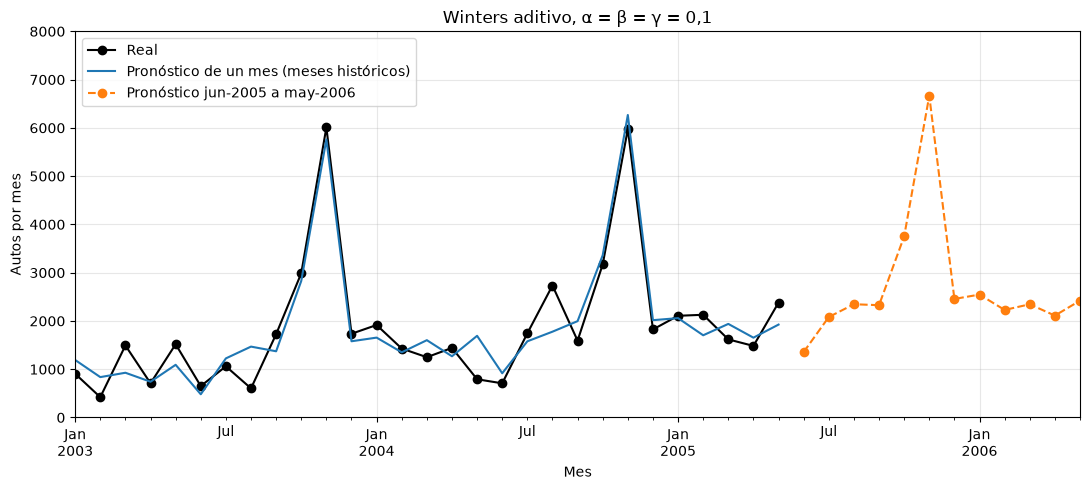

In [10]:
ax = total.plot(color="black", marker="o", label="Real", figsize=(11, 5))
modelo.fittedvalues.plot(ax=ax, label="Pronóstico de un mes (meses históricos)")
pronostico.plot(ax=ax, marker="o", linestyle="--", label="Pronóstico jun-2005 a may-2006")
ax.set_title("Winters aditivo, α = β = γ = 0,1")
ax.set_xlabel("Mes")
ax.set_ylabel("Autos por mes")
ax.set_ylim(0, 8000)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_SALIDA, "pronostico.png"), dpi=150)
plt.show()

## 8. Limitaciones, para el informe

- **Pocos datos:** 29 meses, con solo dos noviembres. Las constantes y los factores estacionales salen de muy pocas observaciones.
- **Posible subestimación:** el modelo ajustado con 2003 y 2004 se quedó corto en enero-mayo de 2005 (sección 5). La demanda anual puede quedar algo baja.
- **Desvío algo optimista:** los valores iniciales se estiman con los mismos datos con que se mide el error, así que el RMSE puede quedar bajo. La consigna ya pide analizar un aumento del 15% en la incertidumbre.
- **Reparto fijo:** mes a mes, la proporción de Clásicos va del 29% al 78% (`01_serie_demanda.ipynb`, sección 7). Con una proporción fija, el desvío de cada línea queda subestimado; se tiene en cuenta en el paso 4.